# Model Training and Evaluation — SmishGuard / Veritxt

Reproducible A–E comparison on the existing private inherited-label corpus. Keep
the established SmishGuard notebook unchanged. **All present results are
retrospective.** Re-splitting historically exposed SMS cannot create an untouched
test. No production model is replaced. Do not distribute data, fitted vocabulary,
private predictions or model coefficients without a separate rights/privacy review.

Synthetic probes are used only for software parity; all reported detection results
use the supplied corpus and its inherited labels. Independent target-task labels,
separate Tagalog/Taglish annotation and prospective SMS remain unresolved.


## Setup

Use Python **3.12 / Unicode 15.0.0** for native Android export. From the repository:
`python -m pip install -r research/retraining-requirements.txt`. Colab can run this
notebook by itself: enable the next cell's install flag. No personal paths or
credentials are embedded. The full pipeline and grouping/export helpers are
included below; the repository is optional.


In [1]:
import os, sys, subprocess
INSTALL_DEPENDENCIES = os.environ.get('SMISHGUARD_INSTALL', '0') == '1'
if INSTALL_DEPENDENCIES:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install',
        'numpy==2.2.6', 'scipy==1.15.3', 'scikit-learn==1.6.1',
        'joblib==1.6.0', 'threadpoolctl==3.7.0', 'cloudpickle==3.1.2',
        'matplotlib==3.10.7', 'pandas==2.3.3'])
print('Python:', sys.version.split()[0])


Python: 3.12.5


## Configure explicit input and private versioned output

Set `SMISHGUARD_DATASET` or edit `DATASET_PATH`. CSV/JSON requires explicit `text`
(or `text_redacted`), `label` and preferably source/language/template metadata.
Accepted labels are ham/smishing or 0/1; generic spam is held for review. For a
Drive ZIP, set `MOUNT_DRIVE=True`, choose its path and set `ZIP_MEMBER` when there
are multiple eligible files. No automatic unrelated-file discovery occurs. ZIP
members are checked then read in memory; no scripts execute or arbitrary extraction.

The default uses the existing audited fitting view. This view is already masked;
it is not raw SMS. `REPLAY_EXISTING=True` verifies and displays a completed sealed
run without fitting, tuning, or re-evaluating its holdout. For a new run use a fresh
output directory and keep the default false. This adapter supports retrospective
inherited-label research; prospective reviewed data uses the repository's separate
intake protocol.


In [2]:
from pathlib import Path
MOUNT_DRIVE = False
if MOUNT_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
DATASET_PATH = Path(os.environ.get('SMISHGUARD_DATASET',
    'runs/bantaytext-20261013/notebook-run-v3/dataset.json'))
ZIP_MEMBER = os.environ.get('SMISHGUARD_ZIP_MEMBER') or None
OUTPUT_PATH = Path(os.environ.get('SMISHGUARD_RETRAIN_RUN',
    'runs/retraining-20261013/notebook-run-v1'))
REPLAY_EXISTING = os.environ.get('SMISHGUARD_REPLAY', '0') == '1'
SEED = 42
if not DATASET_PATH.is_file():
    raise FileNotFoundError('Set DATASET_PATH / SMISHGUARD_DATASET to your authorized private CSV/JSON/ZIP. No fallback dataset is used.')


## Audited implementation

Only whitespace is collapsed. Raw text/original labels remain in the private
ledger. Exact conflicting labels and malformed/flagged records are held. The
label-blind near-template heuristic combines known template metadata with normalized
SequenceMatcher components at 0.85; Unicode casefold exact matches are also grouped.
Source-scoped campaign/sender/conversation groups are included if provided.

Twenty stratified group folds allocate 14/3/3, targeting 70/15/15. Actual counts
can differ. Every partition must have both classes and no group overlap; infeasible
splits fail, with no seed search or random fallback. Source-held-out stress tests
remain separate because three whole sources cannot represent a 70/15/15 split.
Chronological evaluation requires verified receipt timestamps, currently absent.

Every calibration fold fits its own TF-IDF/classifier using outer training only;
OOF margins fit the sigmoid, followed by a final training-only classifier refit.
Compare raw versus calibrated modes. This can shift score scale and is not a
guarantee of calibrated probabilities under real-traffic prevalence.


In [3]:
PIPELINE_SOURCE = '"""Versioned A–E research comparison; private input/output, no production mutations.\n\nOnly explicit inherited mappings are admitted. Final evaluation is separate from\nfitting/selection, checks frozen hashes, and refuses repeated evaluation.\n"""\nfrom collections import Counter, defaultdict\nfrom pathlib import Path\nimport argparse\nimport csv\nimport hashlib\nimport importlib.metadata\nimport importlib.util\nimport io\nimport json\nimport pickle\nimport platform\nimport re\nimport stat\nimport sys\nimport time\nimport unicodedata\nimport warnings\nimport zipfile\n\nimport numpy as np\nfrom sklearn.feature_extraction.text import TfidfVectorizer\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.svm import LinearSVC\nfrom sklearn.naive_bayes import MultinomialNB\nfrom sklearn.model_selection import StratifiedGroupKFold\nfrom sklearn.pipeline import Pipeline, FeatureUnion\nfrom sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,\n    confusion_matrix, average_precision_score, precision_recall_curve, auc,\n    roc_auc_score, brier_score_loss)\nfrom sklearn.calibration import calibration_curve\nfrom threadpoolctl import threadpool_limits\n\n\nfrom difflib import SequenceMatcher\nURL = re.compile(r"https?://\\S+|www\\.\\S+", re.I)\n\ndef template_key(text):\n    # Label-blind grouping uses a broader normalization than the training features.\n    text = URL.sub(\' \', text.lower())\n    text = re.sub(r\'\\bzz(?:url|number|email)zz\\b|[0-9]+\', \' \', text)\n    return re.sub(r\'\\s+\', \' \', re.sub(r\'[^a-z]+\', \' \', text)).strip()\n\ndef make_groups(rows):\n    texts = [template_key(r[\'text\']) for r in rows]\n    counts = [Counter(t) for t in texts]\n    parent = list(range(len(rows)))\n    def root(i):\n        while parent[i] != i:\n            parent[i] = parent[parent[i]]\n            i = parent[i]\n        return i\n    for i in range(len(rows)):\n        for j in range(i):\n            if root(i) == root(j):\n                continue\n            supplied_equal = bool(rows[i].get(\'template_group\')) and rows[i].get(\'template_group\') == rows[j].get(\'template_group\')\n            if texts[i] == texts[j] or supplied_equal:\n                parent[root(i)] = root(j)\n                continue\n            total = len(texts[i])+len(texts[j])\n            if 2*min(len(texts[i]),len(texts[j]))/max(1,total) < .85:\n                continue\n            bound = 2*sum(min(v,counts[j].get(c,0)) for c,v in counts[i].items())/max(1,total)\n            if bound >= .85 and SequenceMatcher(None,texts[i],texts[j],autojunk=False).ratio() >= .85:\n                parent[root(i)] = root(j)\n    return np.array([root(i) for i in range(len(rows))])\n\ndef ranges(points):\n    result=[]\n    for i in points:\n        if result and result[-1][1]+1==i:result[-1][1]=i\n        else:result.append([i,i])\n    return result\n\ndef unicode_contract():\n    # Freeze Python\'s Unicode properties, including numeric/underscore word chars,\n    # full lowercase expansion, and context-sensitive Greek final sigma.\n    word=[];lower={};cased=[];ignorable=[]\n    for i in range(sys.maxunicode+1):\n        c=chr(i)\n        if c.isalnum() or c=="_":word.append(i)\n        if c.lower()!=c:lower[str(i)]=c.lower()\n        if c.islower() or c.isupper() or c.istitle():cased.append(i)\n        if ("AΣ"+c+"A").lower()[1]=="σ" and ("AΣ"+c+" ").lower()[1]=="ς":ignorable.append(i)\n    return dict(unicode_version=unicodedata.unidata_version,word_ranges=ranges(word),lowercase_map=lower,\n                cased_ranges=ranges(cased),case_ignorable_ranges=ranges(ignorable))\n\nPOLICY = dict(precision_floor=.90, fpr_ceiling=.02, minimum_tp=5,\n    objective=\'recall, then phishing F1, average precision, smaller serialized model\',\n    status=\'Provisional research goals; independent deployment acceptance pending\')\nMAX_ZIP_BYTES = 100_000_000\nLABELS = {\'ham\': 0, \'smishing\': 1, \'0\': 0, \'1\': 1}\n\n\ndef save(path, value):\n    Path(path).write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False), encoding=\'utf-8\')\n\n\ndef load(path):\n    return json.loads(Path(path).read_text(encoding=\'utf-8-sig\'))\n\n\ndef digest(path):\n    return hashlib.sha256(Path(path).read_bytes()).hexdigest()\n\n\ndef label_value(value):\n    if type(value) is int and value in (0, 1):\n        return value\n    if isinstance(value, str) and value in LABELS:\n        return LABELS[value]\n    raise ValueError(\'Unsupported label: explicit ham/smishing or 0/1 required; spam is not automatically phishing\')\n\n\ndef read_input(path, member=None):\n    """Strict UTF-8; ZIP is read in memory, never arbitrary extractall or execution."""\n    path = Path(path)\n    if not path.is_file():\n        raise FileNotFoundError(f\'Dataset does not exist: {path}. Set DATASET_PATH to the reviewed CSV/JSON or ZIP.\')\n    name = path.name\n    payload = path.read_bytes()\n    if path.suffix.lower() == \'.zip\':\n        with zipfile.ZipFile(io.BytesIO(payload)) as archive:\n            entries = archive.infolist()\n            if sum(e.file_size for e in entries) > MAX_ZIP_BYTES:\n                raise ValueError(\'ZIP exceeds 100 MB uncompressed research input limit\')\n            for e in entries:\n                parts = e.filename.replace(\'\\\\\', \'/\').split(\'/\')\n                if e.filename.startswith((\'/\', \'\\\\\')) or \'..\' in parts or \':\' in e.filename or stat.S_ISLNK(e.external_attr >> 16):\n                    raise ValueError(\'Unsafe archive member\')\n            candidates = [e.filename for e in entries if not e.is_dir() and Path(e.filename).suffix.lower() in (\'.csv\', \'.json\')]\n            if member is None and len(candidates) != 1:\n                raise ValueError(\'ZIP has multiple/no CSV/JSON datasets. Set ZIP_MEMBER explicitly; no fallback selection.\')\n            name = member or candidates[0]\n            if name not in candidates:\n                raise ValueError(\'Requested ZIP member is absent or unsupported\')\n            payload = archive.read(name)\n    text = payload.decode(\'utf-8-sig\', errors=\'strict\')\n    if Path(name).suffix.lower() == \'.json\':\n        records = json.loads(text)\n        if not isinstance(records, list) or not all(isinstance(r, dict) for r in records):\n            raise ValueError(\'JSON dataset must be a list of record objects\')\n    elif Path(name).suffix.lower() == \'.csv\':\n        reader = csv.DictReader(io.StringIO(text, newline=\'\'), strict=True)\n        if not reader.fieldnames or len(set(reader.fieldnames)) != len(reader.fieldnames):\n            raise ValueError(\'Missing or duplicate CSV headers\')\n        records = list(reader)\n        if any(None in r or any(v is None for v in r.values()) for r in records):\n            raise ValueError(\'Malformed CSV row width\')\n    else:\n        raise ValueError(\'Use an explicit UTF-8 CSV, JSON or ZIP input\')\n    if not records:\n        raise ValueError(\'Dataset contains no records\')\n    return records, dict(container_sha256=digest(path), member=name,\n        member_sha256=hashlib.sha256(payload).hexdigest(), loaded_records=len(records), encoding=\'strict UTF-8\')\n\n\ndef normalized(text):\n    # Preserve case, spelling, URLs, numbers and punctuation. No translation/NFC rewriting.\n    return re.sub(r\'\\s+\', \' \', text).strip()\n\n\ndef audit_records(records):\n    staged, ledger = [], []\n    ids = set()\n    for i, record in enumerate(records):\n        identity = str(record.get(\'id\', f\'row-{i:06d}\'))\n        if identity in ids:\n            raise ValueError(\'Duplicate record IDs; resolve lineage before training\')\n        ids.add(identity)\n        raw = record.get(\'text\', record.get(\'text_redacted\'))\n        reason = None\n        if not isinstance(raw, str) or not raw.strip():\n            reason = \'missing_or_empty_text\'\n        elif \'\\ufffd\' in raw or \'\\x00\' in raw or any(0xd800 <= ord(c) <= 0xdfff for c in raw):\n            reason = \'malformed_text_or_encoding\'\n        try:\n            label = label_value(record.get(\'label\'))\n        except ValueError:\n            label = None\n            reason = reason or \'unsupported_label_requires_review\'\n        if str(record.get(\'needs_review\', \'\')).lower() == \'true\':\n            reason = reason or \'pending_manual_review\'\n        text = normalized(raw) if isinstance(raw, str) else \'\'\n        key = text.casefold()\n        staged.append(dict(record, id=identity, raw_text=raw, original_label=record.get(\'label\'),\n            text=text, label=label, source=record.get(\'source\') or \'Unknown\',\n            language=record.get(\'language\') or \'Unknown\', category=record.get(\'category\') or \'Unknown\'))\n        ledger.append(dict(row=i, id=identity, reason=reason, text_changed=raw != text, key_sha256=hashlib.sha256(key.encode(\'utf-8\', errors=\'surrogatepass\')).hexdigest()))\n    buckets = defaultdict(list)\n    for i, r in enumerate(staged):\n        if r[\'text\'] and r[\'label\'] is not None:\n            buckets[r[\'text\'].casefold()].append(i)\n    conflicts = {key for key, ii in buckets.items() if len({staged[i][\'label\'] for i in ii}) > 1}\n    # Keep matching texts (including cross-source copies) together rather than discard lineage.\n    retained = []\n    for r, entry in zip(staged, ledger):\n        if r[\'text\'].casefold() in conflicts:\n            entry[\'reason\'] = \'conflicting_exact_labels_requires_review\'\n        if entry[\'reason\'] is None:\n            retained.append(r)\n    eligible_buckets = Counter(r[\'text\'].casefold() for r in retained)\n    audit = dict(input_records=len(records), eligible_records=len(retained),\n        unique_raw_messages=len({r.get(\'text\', r.get(\'text_redacted\')) for r in records if isinstance(r.get(\'text\', r.get(\'text_redacted\')), str)}),\n        unique_normalized_messages=len(eligible_buckets), exact_duplicate_extra_rows=sum(v-1 for v in eligible_buckets.values()),\n        conflicting_exact_groups=len(conflicts), exclusions=dict(Counter(e[\'reason\'] for e in ledger if e[\'reason\'])),\n        missing={k:sum(r.get(k) is None or isinstance(r.get(k),str) and not r[k].strip() for r in records)\n            for k in (\'text\',\'label\',\'source\',\'language\',\'category\',\'received_at\',\'sender\',\'campaign\',\'conversation\')},\n        distributions={k:dict(Counter(str(r[k]) for r in retained)) for k in (\'label\',\'source\',\'language\',\'category\')},\n        label_mapping={\'0\':\'ham (inherited, independently unverified)\', \'1\':\'smishing (positive, inherited, independently unverified)\'},\n        preprocessing=\'Collapse whitespace only before vectorization; preserve raw text/original labels privately; no translation/stemming/stopwords\',\n        label_quality=\'No silent relabeling; generic spam/marketing are unsupported without explicit phishing labels\',\n        limitations=[\'Source categories and language metadata are inherited, not verified annotations\',\n            \'Masked existing views have already replaced identifiers/links; raw traffic performance needs independent testing\',\n            \'No verified receipt timestamps: chronological evaluation unavailable\',\n            \'Entire available study corpus historically exposed; no untouched test claim\',\n            \'Published source licenses do not establish all acquisition/privacy/redistribution rights\'])\n    return retained, ledger, audit\n\n\ndef group_records(rows):\n    groups = np.asarray(make_groups(rows))\n    parent = {int(g):int(g) for g in groups}\n    def root(g):\n        while parent[g] != g:\n            parent[g] = parent[parent[g]]\n            g = parent[g]\n        return g\n    for field in (\'campaign\', \'sender\', \'conversation\'):\n        seen = {}\n        for i, row in enumerate(rows):\n            value = row.get(field)\n            if value not in (None, \'\', \'Unknown\'):\n                # Metadata identifiers are scoped to their source, not globally guessed.\n                key = (row[\'source\'], str(value))\n                if key in seen:\n                    parent[root(int(groups[i]))] = root(seen[key])\n                seen[key] = int(groups[i])\n    # Explicit exact Unicode casefold equality guards gaps in the ASCII heuristic.\n    seen = {}\n    for i, row in enumerate(rows):\n        key = row[\'text\'].casefold()\n        if key in seen:\n            parent[root(int(groups[i]))] = root(seen[key])\n        seen[key] = int(groups[i])\n    return np.array([root(int(g)) for g in groups])\n\n\ndef make_split(rows, groups, seed=42):\n    y = np.array([r[\'label\'] for r in rows])\n    if set(y) != {0, 1} or min(Counter(y).values()) < 20 or any(len(set(groups[y==c])) < 20 for c in (0,1)):\n        raise ValueError(\'70/15/15 group split requires >=20 independent groups per class; document a small-sample protocol instead\')\n    folds = [held for _,held in StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=seed).split(np.arange(len(rows)), y, groups)]\n    split = {p:np.concatenate(folds[a:b]).tolist() for p,a,b in [(\'train\',0,14),(\'validation\',14,17),(\'test\',17,20)]}\n    validate_split(rows, groups, split)\n    return split\n\n\ndef validate_split(rows, groups, split):\n    flat = [i for p in split.values() for i in p]\n    if len(flat) != len(rows) or set(flat) != set(range(len(rows))):\n        raise ValueError(\'Partition IDs must form a complete disjoint cover\')\n    for p, ids in split.items():\n        if {rows[i][\'label\'] for i in ids} != {0,1}:\n            raise ValueError(f\'{p} lacks both classes; no favorable-seed retry\')\n        for q, jj in split.items():\n            if p < q and (set(groups[ids]) & set(groups[jj]) or\n                {rows[i][\'text\'].casefold() for i in ids} & {rows[j][\'text\'].casefold() for j in jj}):\n                raise ValueError(\'Exact/near/metadata component crosses partitions\')\n\n\ndef matrix():\n    entries = []\n    for family, algorithm, combined in [(\'A\',\'lr\',False),(\'B\',\'svm\',False),(\'C\',\'svm\',True),(\'D\',\'lr\',True),(\'E\',\'nb\',False)]:\n        settings = [(1,None,[1,1],[3,5]),(2,20000,[1,2],[3,5])]\n        if combined:\n            settings = [(1,None,[1,2],[3,5]),(2,30000,[1,2],[3,5]),(2,15000,[1,2],[3,6])]\n        for df,limit,word,char in settings:\n            for value in ((.03,.1,.3,1.,3.) if algorithm==\'nb\' else (.1,1.,10.)):\n                for weighting in ([None] if algorithm==\'nb\' else [None,\'balanced\']):\n                    entries.append(dict(id=f\'{family}-{len(entries):03d}\',family=family,algorithm=algorithm,combined=combined,\n                        min_df=df,max_features=limit,word_ngrams=word,char_ngrams=char,value=value,class_weight=weighting))\n    # Every family first fits original distribution; paired class-weight comparisons follow.\n    return sorted(entries, key=lambda e:(e[\'class_weight\'] is not None, e[\'family\'], e[\'id\']))\n\n\ndef vectorizer(spec):\n    params = dict(min_df=spec[\'min_df\'],max_features=spec[\'max_features\'],lowercase=True,\n        norm=\'l2\',sublinear_tf=False,smooth_idf=True,stop_words=None)\n    word = TfidfVectorizer(ngram_range=tuple(spec[\'word_ngrams\']), **params)\n    return FeatureUnion([(\'word\',word),(\'char\',TfidfVectorizer(analyzer=\'char_wb\',ngram_range=tuple(spec[\'char_ngrams\']),**params))]) if spec[\'combined\'] else word\n\n\ndef pipeline(spec, seed):\n    if spec[\'algorithm\']==\'lr\':\n        classifier = LogisticRegression(C=spec[\'value\'], class_weight=spec[\'class_weight\'], solver=\'liblinear\', max_iter=2000, random_state=seed)\n    elif spec[\'algorithm\']==\'svm\':\n        classifier = LinearSVC(C=spec[\'value\'],class_weight=spec[\'class_weight\'],dual=\'auto\',max_iter=10000,random_state=seed)\n    else:\n        classifier = MultinomialNB(alpha=spec[\'value\'])\n    return Pipeline([(\'tfidf\',vectorizer(spec)),(\'classifier\',classifier)])\n\n\ndef margins(pipe, texts):\n    if pipe[\'classifier\'].classes_.tolist() != [0,1]:\n        raise ValueError(\'Positive class mapping changed\')\n    x = pipe[\'tfidf\'].transform(texts)\n    c = pipe[\'classifier\']\n    return c.predict_log_proba(x)[:,1]-c.predict_log_proba(x)[:,0] if isinstance(c,MultinomialNB) else c.decision_function(x)\n\n\ndef fit(rows, groups, ids, spec, seed=42):\n    ids = np.array(ids, dtype=int); y = np.array([rows[i][\'label\'] for i in ids]); texts = [rows[i][\'text\'] for i in ids]\n    started = time.perf_counter(); folds=[]; oof=np.full(len(ids),np.nan)\n    for a,b in StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=seed).split(ids,y,groups[ids]):\n        if set(y[a]) != {0,1} or set(y[b]) != {0,1} or set(groups[ids[a]]) & set(groups[ids[b]]):\n            raise ValueError(\'Invalid training-only grouped calibration fold\')\n        p=pipeline(spec,seed).fit([texts[i] for i in a],y[a]); oof[b]=margins(p,[texts[i] for i in b])\n        folds.append(dict(train=ids[a].tolist(),calibration=ids[b].tolist()))\n    if not np.isfinite(oof).all():\n        raise ValueError(\'Incomplete OOF calibration predictions\')\n    cal=LogisticRegression(C=1,solver=\'lbfgs\',random_state=seed).fit(oof.reshape(-1,1),y)\n    if cal.coef_[0,0] <= 0:\n        raise ValueError(\'Nonmonotone calibration: do not export reversed phishing scores\')\n    p=pipeline(spec,seed).fit(texts,y)\n    x=p[\'tfidf\'].transform(texts).tocsr()\n    return dict(pipe=p,calibrator=cal,spec=spec,seed=seed,training_ids=ids.tolist(),calibration_folds=folds,\n        training_seconds=time.perf_counter()-started,feature_count=x.shape[1],\n        sparse_training_bytes=x.data.nbytes+x.indices.nbytes+x.indptr.nbytes)\n\n\ndef score(artifact, texts, mode):\n    if not all(isinstance(t,str) for t in texts):\n        raise ValueError(\'Prediction input must contain strings\')\n    m=margins(artifact[\'pipe\'],[normalized(t) for t in texts])\n    if mode==\'sigmoid\':\n        return artifact[\'calibrator\'].predict_proba(m.reshape(-1,1))[:,1]\n    if artifact[\'spec\'][\'algorithm\']==\'svm\':\n        return m\n    # Stable conversion of log odds for LR/NB.\n    from scipy.special import expit\n    return expit(m)\n\n\ndef metrics(y, scores, threshold, probability):\n    y=np.asarray(y); s=np.asarray(scores); pred=s>=threshold\n    if not len(y) or not np.isfinite(s).all():\n        raise ValueError(\'Nonempty finite scores required\')\n    if probability and ((s<0)|(s>1)).any():\n        raise ValueError(\'Probability must lie in [0,1]\')\n    tn,fp,fn,tp=[int(n) for n in confusion_matrix(y,pred,labels=[0,1]).ravel()]\n    both=set(y)=={0,1}\n    p,r,_=precision_recall_curve(y,s) if both else (None,None,None)\n    return dict(records=len(y),accuracy=float(accuracy_score(y,pred)),precision=float(precision_score(y,pred,zero_division=0)),\n        recall=float(recall_score(y,pred,zero_division=0)),f1=float(f1_score(y,pred,zero_division=0)),\n        macro_f1=float(f1_score(y,pred,labels=[0,1],average=\'macro\',zero_division=0)),\n        average_precision=float(average_precision_score(y,s)) if both else None,\n        pr_auc=float(auc(r,p)) if both else None,roc_auc=float(roc_auc_score(y,s)) if both else None,\n        confusion=dict(tn=tn,fp=fp,fn=fn,tp=tp),fpr=fp/(tn+fp) if tn+fp else None,\n        brier=float(brier_score_loss(y,s)) if probability else None,probability_estimate=probability)\n\n\ndef choose_threshold(y, scores, probability):\n    y=np.asarray(y);s=np.asarray(scores)\n    order=np.argsort(-s,kind=\'stable\'); ordered=s[order]\n    thresholds=np.unique(np.r_[s,np.nextafter(s,np.inf)])\n    cuts=np.searchsorted(-ordered,-thresholds,side=\'right\')\n    tp=np.r_[0,np.cumsum(y[order]==1)][cuts];fp=np.r_[0,np.cumsum(y[order]==0)][cuts]\n    precision=np.divide(tp,tp+fp,out=np.zeros(len(tp)),where=(tp+fp)>0)\n    eligible=np.flatnonzero((precision>=POLICY[\'precision_floor\']) & (fp/max(1,int((y==0).sum()))<=POLICY[\'fpr_ceiling\']) & (tp>=POLICY[\'minimum_tp\']))\n    if not len(eligible):\n        return None\n    j=max(eligible,key=lambda j:(int(tp[j]),2*tp[j]/(tp[j]+fp[j]+int((y==1).sum())),float(thresholds[j])))\n    return dict(threshold=float(thresholds[j]),metrics=metrics(y,s,float(thresholds[j]),probability))\n\n\ndef rank(candidate):\n    m=candidate[\'validation\'];return (m[\'recall\'],m[\'f1\'],m[\'average_precision\'],-candidate[\'artifact_bytes\'],candidate[\'id\'])\n\n\ndef subgroup_metrics(rows, ids, scores, threshold, probability):\n    out={}\n    for field in (\'language\',\'source\',\'category\'):\n        for value in sorted({rows[i][field] for i in ids}):\n            jj=[j for j,i in enumerate(ids) if rows[i][field]==value];y=[rows[ids[j]][\'label\'] for j in jj]\n            support=Counter(y); adequate=len(jj)>=20 and min(support[0],support[1])>=5\n            out[f\'{field}:{value}\']=dict(records=len(jj),ham=support[0],phishing=support[1],\n                adequate_two_class_support=adequate,interpretation=\'descriptive inherited subgroup; not independently validated\',\n                metrics=metrics(y,np.asarray(scores)[jj],threshold,probability) if adequate else None)\n    return out\n\n\ndef robustness(artifact, rows, ids, mode, threshold):\n    # Deterministic surface edits of existing validation SMS, never generated research records.\n    texts=[rows[i][\'text\'] for i in ids];y=[rows[i][\'label\'] for i in ids]\n    original=score(artifact,texts,mode)>=threshold\n    transforms={\'uppercase\':lambda t:t.upper(),\'extra_whitespace\':lambda t:\'  \'+t.replace(\' \',\'  \\t \')+\'  \',\n        \'terminal_punctuation\':lambda t:t+\'!!!\', \'spelling_noise\':lambda t:re.sub(r\'(?i)\\b(account|verify|payment)\\b\',lambda m:{\'account\':\'acc0unt\',\'verify\':\'ver1fy\',\'payment\':\'paym3nt\'}[m[0].lower()],t),\n        \'taglish_spelling\':lambda t:re.sub(r\'(?i)\\b(hindi|kailangan|ngayon)\\b\',lambda m:{\'hindi\':\'hndi\',\'kailangan\':\'kelangan\',\'ngayon\':\'ngaun\'}[m[0].lower()],t)}\n    out={}\n    for name,transform in transforms.items():\n        edited=[transform(t) for t in texts];changed=[i for i,(a,b) in enumerate(zip(texts,edited)) if a!=b]\n        s=score(artifact,edited,mode)\n        out[name]=dict(records=len(ids),changed_records=len(changed),prediction_flips=int(np.sum((s>=threshold)!=original)),\n            metrics=metrics(y,s,threshold,mode==\'sigmoid\' or artifact[\'spec\'][\'algorithm\']!=\'svm\'),\n            changed_subset_metrics=metrics(np.asarray(y)[changed],s[changed],threshold,mode==\'sigmoid\' or artifact[\'spec\'][\'algorithm\']!=\'svm\') if changed else None,\n            limitation=\'Assumed label-preserving surface edit; spelling variants need manual semantic review; no adversarial-security claim\')\n    return out\n\n\ndef environment():\n    versions={n:importlib.metadata.version(n) for n in (\'numpy\',\'scipy\',\'scikit-learn\',\'matplotlib\',\'joblib\',\'threadpoolctl\')}\n    return dict(python=sys.version,unicode=unicodedata.unidata_version,platform=platform.platform(),packages=versions,\n        threads=1,transformer=dict(torch_available=bool(importlib.util.find_spec(\'torch\')),\n        transformers_available=bool(importlib.util.find_spec(\'transformers\')),\n        checkpoint_cached=bool(list((Path.home()/\'.cache/huggingface/hub\').glob(\'models--*xlm*\'))),\n        status=\'XLM-R not executed: current research env lacks torch/transformers and a pinned local checkpoint. Existing mBERT is a different model.\'))\n\n\ndef train(dataset, output, history, member=None, seed=42):\n    output=Path(output)\n    if history!=\'previously_used\':\n        raise ValueError(\'This inherited-label adapter supports retrospective research only; use reviewed prospective intake workflow for new final data\')\n    records,identity=read_input(dataset,member)\n    rows,ledger,audit=audit_records(records)\n    output.mkdir(parents=True,exist_ok=False)\n    save(output/\'original-records.json\',records);save(output/\'dataset.json\',rows);save(output/\'cleaning-ledger.json\',ledger)\n    groups=group_records(rows);split=make_split(rows,groups,seed)\n    audit.update(template_groups=len(set(groups)),mixed_label_groups=sum(len({rows[i][\'label\'] for i in range(len(rows)) if groups[i]==g})>1 for g in set(groups)),\n        group_policy=\'Existing label-blind .85 normalized SequenceMatcher connected components plus exact Unicode casefold and supplied template/campaign/sender/conversation groups\',\n        source_isolation=\'Sources deliberately span partitions; only three sources cannot support 70/15/15 whole-source splits. Source-transfer diagnostics are separate.\',\n        input=identity,partitions={p:dict(records=len(ii),groups=len(set(groups[ii])),labels=dict(Counter(str(rows[i][\'label\']) for i in ii)),fraction=len(ii)/len(rows)) for p,ii in split.items()},\n        pairwise_group_overlap={a+\'-\'+b:len(set(groups[split[a]])&set(groups[split[b]])) for a in split for b in split if a<b})\n    save(output/\'data-audit.json\',audit);save(output/\'splits.json\',dict(partitions=split,groups=groups.tolist(),seed=seed,target=[.70,.15,.15]))\n    save(output/\'environment.json\',environment())\n    specs=matrix();save(output/\'configuration.json\',dict(matrix=specs,policy=POLICY,history=history,\n        calibration=\'3 training-only group folds, fold-local feature fitting, OOF sigmoid then train-only refit; no resampling\',\n        ranking=\'Compare raw and calibrated scores separately; SVM margins never probabilities\',\n        seed=seed,repeat_training_seeds=[seed,seed+1,seed+2]))\n    val=split[\'validation\'];texts=[rows[i][\'text\'] for i in val];y=[rows[i][\'label\'] for i in val]\n    candidates=[];failures=[];start=time.perf_counter()\n    with threadpool_limits(limits=1):\n        for number,spec in enumerate(specs,1):\n            folder=output/spec[\'id\'];folder.mkdir()\n            try:\n                with warnings.catch_warnings(record=True) as caught:\n                    warnings.simplefilter(\'always\');a=fit(rows,groups,split[\'train\'],spec,seed)\n                if caught:\n                    raise ValueError(\'Fitting warning: \'+ \';\'.join(type(w.message).__name__ for w in caught))\n                model=folder/\'pipeline.pkl\';model.write_bytes(pickle.dumps(a,protocol=5))\n                for mode in (\'raw\',\'sigmoid\'):\n                    s=score(a,texts,mode);probability=mode==\'sigmoid\' or spec[\'algorithm\']!=\'svm\'\n                    default=metrics(y,s,0 if spec[\'algorithm\']==\'svm\' and mode==\'raw\' else .5,probability)\n                    op=choose_threshold(y,s,probability)\n                    row=dict(id=spec[\'id\']+\'-\'+mode,fit_id=spec[\'id\'],family=spec[\'family\'],spec=spec,mode=mode,\n                        threshold=op[\'threshold\'] if op else None,validation=op[\'metrics\'] if op else None,\n                        default_validation=default,feasible=op is not None,training_seconds=a[\'training_seconds\'],\n                        artifact_bytes=model.stat().st_size,feature_count=a[\'feature_count\'],sparse_training_bytes=a[\'sparse_training_bytes\'])\n                    save(folder/f\'validation-{mode}.json\',dict(indices=val,labels=y,scores=s.tolist(),result=row))\n                    candidates.append(row)\n            except (ValueError,RuntimeError) as error:\n                failures.append(dict(id=spec[\'id\'],reason=str(error)))\n            if number%10==0:\n                print(f\'Fitted {number}/{len(specs)} configurations\',flush=True)\n        winners={family:max([c for c in candidates if c[\'family\']==family and c[\'feasible\']],key=rank) for family in \'ABCDE\' if any(c[\'family\']==family and c[\'feasible\'] for c in candidates)}\n        selected=max(winners.values(),key=rank) if winners else None\n        # Seeds change fitting/calibration only; split, spec/mode and threshold stay locked.\n        variability=[]\n        if selected:\n            for repeat_seed in (seed+1,seed+2):\n                a=fit(rows,groups,split[\'train\'],selected[\'spec\'],repeat_seed)\n                variability.append(dict(seed=repeat_seed,validation=metrics(y,score(a,texts,selected[\'mode\']),selected[\'threshold\'], selected[\'mode\']==\'sigmoid\' or selected[\'spec\'][\'algorithm\']!=\'svm\')))\n        save(output/\'validation-results.json\',dict(candidates=candidates,failures=failures,seconds=time.perf_counter()-start))\n        save(output/\'selection.json\',dict(selected=selected,family_winners=winners,policy=POLICY,\n            history=history,interpretation=\'Validation-selected retrospective research candidate; production unchanged; no future-traffic winner\',\n            seed_variability=variability))\n        if selected:\n            a=pickle.loads((output/selected[\'fit_id\']/\'pipeline.pkl\').read_bytes())\n            save(output/\'robustness-validation.json\',robustness(a,rows,val,selected[\'mode\'],selected[\'threshold\']))\n            save(output/\'subgroups-validation.json\',subgroup_metrics(rows,val,score(a,texts,selected[\'mode\']),selected[\'threshold\'],selected[\'mode\']==\'sigmoid\' or selected[\'spec\'][\'algorithm\']!=\'svm\'))\n            diagnostic_models(rows,groups,split,selected,output)\n            export_candidate(a,selected,output)\n    protected={str(p.relative_to(output)):digest(p) for p in output.rglob(\'*\') if p.is_file() and p.name!=\'freeze.json\'}\n    save(output/\'freeze.json\',dict(files=protected,source_sha256=digest(Path(__file__)),dataset_sha256=digest(dataset),\n        history=history,selected_id=selected[\'id\'] if selected else None))\n    plot_development(output)\n    print(f\'Selected: {selected["id"] if selected else "none feasible"}; frozen before holdout prediction\',flush=True)\n    return output\n\n\ndef diagnostic_models(rows,groups,split,selected,output):\n    ids=split[\'train\']; val=split[\'validation\'];y=[rows[i][\'label\'] for i in val]; out={}\n    # Shortcut controls fit on training only. They never enter candidate selection.\n    for view in (\'source_only\',\'link_marker_only\'):\n        def representation(r):\n            return r[\'source\'] if view==\'source_only\' else (\'haslink\' if re.search(r\'(?i)zzurlzz|https?://|www\\.\',r[\'text\']) else \'nolink\')\n        p=Pipeline([(\'v\',TfidfVectorizer()),(\'m\',LogisticRegression(random_state=42))]).fit([representation(rows[i]) for i in ids],[rows[i][\'label\'] for i in ids])\n        s=p.predict_proba([representation(rows[i]) for i in val])[:,1]\n        out[view]=metrics(y,s,.5,True)\n    artifact=pickle.loads((output/selected[\'fit_id\']/\'pipeline.pkl\').read_bytes())\n    texts=[rows[i][\'text\'] for i in val]\n    s=score(artifact,[re.sub(r\'(?i)zzurlzz|https?://\\S+|www\\.\\S+\',\' \',t) for t in texts],selected[\'mode\'])\n    out[\'selected_frozen_url_removal\']=dict(metrics=metrics(y,s,selected[\'threshold\'],selected[\'mode\']==\'sigmoid\' or selected[\'spec\'][\'algorithm\']!=\'svm\'),\n        interpretation=\'Frozen feature ablation on validation; not a newly trained model or a label-preserving robustness claim\')\n    save(output/\'shortcut-validation.json\',out)\n    # Transfer diagnostics: frozen spec/mode/threshold, train complement only.\n    # These use validation rows from a source, never the reserved holdout.\n    transfer={}\n    for source in sorted({r[\'source\'] for r in rows}):\n        held=[i for i in val if rows[i][\'source\']==source]; held_groups=set(groups[held])\n        training=[i for i in ids if rows[i][\'source\']!=source and groups[i] not in held_groups]\n        if not held or {rows[i][\'label\'] for i in training}!={0,1}:\n            transfer[source]=dict(status=\'Insufficient supported complement\');continue\n        a=fit(rows,groups,training,selected[\'spec\'],42)\n        s=score(a,[rows[i][\'text\'] for i in held],selected[\'mode\'])\n        transfer[source]=dict(training_records=len(training),held_records=len(held),\n            metrics=metrics([rows[i][\'label\'] for i in held],s,selected[\'threshold\'],selected[\'mode\']==\'sigmoid\' or selected[\'spec\'][\'algorithm\']!=\'svm\'),\n            status=\'Development transfer stress test; selected spec/threshold influenced by these validation records; not independent source-generalization evidence\')\n    save(output/\'source-transfer-validation.json\',transfer)\n\n\ndef export_candidate(artifact, selected, output):\n    if unicodedata.unidata_version!=\'15.0.0\':\n        raise ValueError(\'Native Unicode export needs Python 3.12 / Unicode 15.0.0\')\n    pipe=artifact[\'pipe\'];clf=pipe[\'classifier\'];feature=pipe[\'tfidf\']\n    blocks=feature.transformer_list if isinstance(feature,FeatureUnion) else [(\'word\',feature)]\n    exported=[]\n    for name,v in blocks:\n        exported.append(dict(analyzer=v.analyzer,ngram_range=list(v.ngram_range),\n            vocabulary=v.get_feature_names_out().tolist(),idf=v.idf_.tolist(),norm=\'l2\',tf=\'raw\'))\n    weights=(clf.feature_log_prob_[1]-clf.feature_log_prob_[0]) if isinstance(clf,MultinomialNB) else clf.coef_[0]\n    bias=float(clf.class_log_prior_[1]-clf.class_log_prior_[0]) if isinstance(clf,MultinomialNB) else float(clf.intercept_[0])\n    calibration=(dict(a=float(artifact[\'calibrator\'].coef_[0,0]),b=float(artifact[\'calibrator\'].intercept_[0])) if selected[\'mode\']==\'sigmoid\'\n        else dict(a=1.,b=0.) if selected[\'spec\'][\'algorithm\']!=\'svm\' else None)\n    contract=dict(schema_version=7,research_contract=\'word-char-linear-v1\',algorithm=selected[\'spec\'][\'algorithm\'],\n        input_view=\'whitespace_normalized_existing_masked_text\',blocks=exported,weights=weights.tolist(),bias=bias,\n        calibration=calibration,threshold=selected[\'threshold\'],threshold_comparison=\'greater_or_equal\',\n        classes=[\'ham\',\'smishing\'],positive_class=\'smishing\',unicode=unicode_contract(),\n        whitespace_codepoints=[i for i in range(sys.maxunicode+1) if chr(i).isspace()],\n        probability_approved=False,automatic_warnings_approved=False,evaluation_status=\'retrospective_inherited_labels\',\n        preprocessing=\'Whitespace collapse; Python Unicode lowercase; word min2 no stopwords; char_wb codepoint slices; independent block L2 norms\',\n        configuration=selected,calibration_status=\'training_OOF_fitted; heldout reliability diagnostic; no real-traffic probability claim\')\n    save(output/\'candidate-model.json\',contract)\n    texts=[\'\', \'   \', \'\\x00\', \'??? 123 🌟\', \'qzxv qzxv\', \'Hello, kumusta na?\',\n        \'Do not share your OTP. Payment PHP 123.45 received.\', \'I-verify ang account mo sa https://example.invalid\',\n        \'ACCOUNT\\taccount\\nverify\', \'İ Σ ΟΣ 𐐀 Ñ ñ e\\u0301\', \'A\\u00a0B\\u2003hello\',\n        \'single a I x\', \' a   b  \', \'hi\', \'Paki bayad ngayon, wag i-share ang code.\', \'𝔸𝔹𝔠 verify\',\n        \'one\\u001ctwo\', \'💬code\\u2028hello\', \'x\'*20,\'hello \'*2000]\n    cases=[];reference=score(artifact,texts,selected[\'mode\'])\n    for text,s in zip(texts,reference):\n        x=feature.transform([normalized(text)]).tocsr()\n        cases.append(dict(text=text,score=float(s),suspicious=bool(s>=selected[\'threshold\']),\n            features={str(i):float(v) for i,v in zip(x.indices,x.data)}))\n    save(output/\'candidate-cases.json\',dict(cases=cases,synthetic=True,tolerance=1e-10))\n\n\ndef verify_freeze(dataset, output):\n    frozen=load(output/\'freeze.json\')\n    if digest(dataset)!=frozen[\'dataset_sha256\'] or digest(Path(__file__))!=frozen[\'source_sha256\']:\n        raise ValueError(\'Dataset or code changed since freeze\')\n    for name,sha in frozen[\'files\'].items():\n        if digest(output/name)!=sha:\n            raise ValueError(\'Frozen artifact changed: \'+name)\n    return frozen\n\n\ndef evaluate(dataset, output):\n    output=Path(output); frozen=verify_freeze(dataset,output)\n    selection=load(output/\'selection.json\');rows=load(output/\'dataset.json\');manifest=load(output/\'splits.json\')\n    split=manifest[\'partitions\'];groups=np.array(manifest[\'groups\']);validate_split(rows,groups,split)\n    # Marker precedes any test transformation: interrupted evaluation also fails closed.\n    with (output/\'holdout-started.json\').open(\'x\',encoding=\'utf-8\') as handle:\n        json.dump(dict(freeze_sha256=digest(output/\'freeze.json\'),history=frozen[\'history\']),handle)\n    ids=split[\'test\'];texts=[rows[i][\'text\'] for i in ids];y=[rows[i][\'label\'] for i in ids]; results={}\n    with threadpool_limits(limits=1):\n        for family,c in selection[\'family_winners\'].items():\n            a=pickle.loads((output/c[\'fit_id\']/\'pipeline.pkl\').read_bytes())\n            start=time.perf_counter();s=score(a,texts,c[\'mode\']);batch=time.perf_counter()-start\n            # Warm single-SMS end-to-end latency, fixed representative prefix, no labels used.\n            latency=[]\n            for text in texts[:min(100,len(texts))]:\n                start=time.perf_counter();score(a,[text],c[\'mode\']);latency.append((time.perf_counter()-start)*1000)\n            probability=c[\'mode\']==\'sigmoid\' or c[\'spec\'][\'algorithm\']!=\'svm\'\n            m=metrics(y,s,c[\'threshold\'],probability)\n            results[family]=dict(candidate=c,holdout=m,subgroups=subgroup_metrics(rows,ids,s,c[\'threshold\'],probability),\n                latency=dict(host_batch_ms_per_sms=1000*batch/len(texts),host_single_p50_ms=float(np.median(latency)),host_single_p95_ms=float(np.quantile(latency,.95)),samples=len(latency),android=\'Separate JVM and instrumentation checks; physical-device benchmark pending\'),\n                predictions_file=f\'holdout-{family}-predictions.json\')\n            save(output/f\'holdout-{family}-predictions.json\',dict(indices=ids,labels=y,scores=s.tolist(),threshold=c[\'threshold\']))\n    selected=selection[\'selected\']\n    if selected:\n        family=selected[\'family\'];predictions=load(output/f\'holdout-{family}-predictions.json\')\n        # Anonymous ledger; original texts remain private in dataset.json.\n        errors=[dict(row_index=i,id=rows[i][\'id\'],label=int(label),score=s,kind=\'false_positive\' if label==0 else \'false_negative\',human_label=\'\',review_reference=\'\')\n            for i,label,s in zip(ids,y,predictions[\'scores\']) if (s>=selected[\'threshold\'])!=bool(label)]\n        save(output/\'private-error-review.json\',errors)\n        results[family][\'conditional_cluster_intervals\']=bootstrap(y,predictions[\'scores\'],groups[ids],selected[\'threshold\'])\n    save(output/\'holdout-results.json\',dict(results=results,selected_id=selected[\'id\'] if selected else None,\n        history=frozen[\'history\'],interpretation=\'Historically exposed holdout; family winners locked before this run. Cannot establish prospective performance. Never reselect using these results.\'))\n    plot_holdout(output)\n    print(\'Locked retrospective holdout evaluation complete; no production model replaced\')\n\n\ndef bootstrap(y,scores,groups,threshold,repetitions=1000):\n    y=np.array(y);s=np.array(scores);groups=np.array(groups);unique=np.unique(groups);rng=np.random.default_rng(42); samples=[]\n    members={g:np.flatnonzero(groups==g) for g in unique}\n    for _ in range(repetitions):\n        ii=np.concatenate([members[g] for g in rng.choice(unique,len(unique),replace=True)])\n        if set(y[ii])=={0,1}:\n            samples.append([recall_score(y[ii],s[ii]>=threshold),precision_score(y[ii],s[ii]>=threshold,zero_division=0),f1_score(y[ii],s[ii]>=threshold)])\n    if not samples:\n        return dict(status=\'Insufficient two-class bootstrap support\')\n    intervals=np.quantile(samples,[.025,.975],axis=0)\n    return dict(seed=42,repetitions=repetitions,valid=len(samples),\n        intervals={name:dict(low=float(intervals[0,j]),high=float(intervals[1,j])) for j,name in enumerate((\'recall\',\'precision\',\'f1\'))},\n        scope=\'Fixed selected model/threshold, cluster percentile bootstrap; excludes label, exposure, selection and training uncertainty\')\n\n\ndef plotting():\n    import matplotlib\n    matplotlib.use(\'Agg\')\n    import matplotlib.pyplot as plt\n    return plt\n\n\ndef plot_development(output):\n    plt=plotting();audit=load(output/\'data-audit.json\');fig,axes=plt.subplots(1,3,figsize=(13,4))\n    for ax,field in zip(axes,(\'label\',\'language\',\'source\')):\n        d=audit[\'distributions\'][field]; ax.bar(d.keys(),d.values());ax.set_title(field+\' coverage\');ax.tick_params(axis=\'x\',rotation=20)\n    fig.tight_layout();fig.savefig(output/\'coverage.png\',dpi=160);plt.close(fig)\n\n\ndef plot_holdout(output):\n    plt=plotting();results=load(output/\'holdout-results.json\')[\'results\']\n    if not results:return\n    fig,axes=plt.subplots(2,len(results),figsize=(4*len(results),7),squeeze=False)\n    fig_pr,ax_pr=plt.subplots(figsize=(7,5));fig_cal,ax_cal=plt.subplots(figsize=(7,5))\n    for j,(family,item) in enumerate(results.items()):\n        pred=load(output/item[\'predictions_file\']);y=pred[\'labels\'];s=pred[\'scores\'];m=item[\'holdout\'];c=m[\'confusion\']\n        cm=np.array([[c[\'tn\'],c[\'fp\']],[c[\'fn\'],c[\'tp\']]])\n        axes[0,j].imshow(cm,cmap=\'Blues\');axes[0,j].set_title(f\'Family {family}: retrospective\')\n        axes[0,j].set_xticks([0,1],[\'ham\',\'phishing\']);axes[0,j].set_yticks([0,1],[\'ham\',\'phishing\']);axes[0,j].set_xlabel(\'Predicted\');axes[0,j].set_ylabel(\'True inherited label\')\n        for a in range(2):\n            for b in range(2):axes[0,j].text(b,a,str(cm[a,b]),ha=\'center\',va=\'center\')\n        axes[1,j].bar([\'P\',\'R\',\'F1\',\'Macro F1\'],[m[\'precision\'],m[\'recall\'],m[\'f1\'],m[\'macro_f1\']]);axes[1,j].set_ylim(0,1)\n        p,r,_=precision_recall_curve(y,s);ax_pr.plot(r,p,label=f\'{family} AP={m["average_precision"]:.3f}\')\n        if m[\'probability_estimate\']:\n            fraction,mean=calibration_curve(y,s,n_bins=8,strategy=\'quantile\');ax_cal.plot(mean,fraction,\'o-\',label=f\'{family} Brier={m["brier"]:.4f}\')\n    fig.tight_layout();fig.savefig(output/\'confusion-and-comparison.png\',dpi=160);plt.close(fig)\n    ax_pr.set(xlabel=\'Phishing recall\',ylabel=\'Phishing precision\',title=\'Historically exposed holdout PR curves\');ax_pr.legend();fig_pr.tight_layout();fig_pr.savefig(output/\'precision-recall.png\',dpi=160);plt.close(fig_pr)\n    ax_cal.plot([0,1],[0,1],\'--\',color=\'gray\');ax_cal.set(xlabel=\'Mean estimated probability\',ylabel=\'Observed inherited phishing fraction\',title=\'Retrospective reliability; quantile bins\');ax_cal.legend();fig_cal.tight_layout();fig_cal.savefig(output/\'reliability.png\',dpi=160);plt.close(fig_cal)\n\n\ndef main():\n    p=argparse.ArgumentParser(description=__doc__);p.add_argument(\'command\',choices=[\'train\',\'evaluate\']);p.add_argument(\'dataset\',type=Path);p.add_argument(\'output\',type=Path)\n    p.add_argument(\'--history\',choices=[\'previously_used\'],default=\'previously_used\');p.add_argument(\'--zip-member\');p.add_argument(\'--seed\',type=int,default=42)\n    args=p.parse_args()\n    if args.command==\'train\':train(args.dataset,args.output,args.history,args.zip_member,args.seed)\n    else:evaluate(args.dataset,args.output)\n\n\nif __name__==\'__main__\':main()\n'

In [4]:
import importlib.util, hashlib
try:
    from smishguard import retraining as pipeline
except ModuleNotFoundError:
    support = OUTPUT_PATH.parent / '_notebook_support'
    support.mkdir(parents=True, exist_ok=True)
    module_path = support / ('pipeline-' + hashlib.sha256(PIPELINE_SOURCE.encode()).hexdigest()[:12] + '.py')
    if not module_path.exists():
        module_path.write_text(PIPELINE_SOURCE, encoding='utf-8')
    spec = importlib.util.spec_from_file_location('standalone_smishguard_retraining', module_path)
    pipeline = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(pipeline)
print('Configured families:', sorted({s['family'] for s in pipeline.matrix()}))
print('Fit configurations:', len(pipeline.matrix()), 'each compared raw and sigmoid')


Configured families: ['A', 'B', 'C', 'D', 'E']
Fit configurations: 70 each compared raw and sigmoid


## Fit and select using training / validation only

A: word TF-IDF + LR; B: word TF-IDF + Linear SVM; C: word (1,2) + char_wb (3,5)
TF-IDF + SVM; D: same features + LR; E: word TF-IDF + NB. Tune C/class weights,
min_df, feature limits, n-gram variant and NB alpha (0.03/0.1/0.3/1/3).
Original distribution is fitted first; no validation/test resampling or SMOTE.

Provisional validation operating goals: precision >=0.90, FPR <=0.02 and >=5 TP.
Maximize recall, then phishing F1, AP, smaller artifact. Fail infeasible candidates.
These are research goals, pending an agreed deployment requirement. All family
winners, thresholds and files are sealed before holdout evaluation. The historical
baseline replay is saved separately in the audit-v1 artifact when available.


In [5]:
if REPLAY_EXISTING:
    pipeline.verify_freeze(DATASET_PATH, OUTPUT_PATH)
else:
    pipeline.train(DATASET_PATH, OUTPUT_PATH, history='previously_used',
                   member=ZIP_MEMBER, seed=SEED)
audit = pipeline.load(OUTPUT_PATH / 'data-audit.json')
print({k:audit[k] for k in ('input_records','eligible_records','unique_normalized_messages',
    'template_groups','exclusions','distributions','partitions','pairwise_group_overlap')})
selection = pipeline.load(OUTPUT_PATH / 'selection.json')
print('Selected research configuration:', selection['selected']['id'] if selection['selected'] else None)
print('Operating policy:', selection['policy'])
baseline = OUTPUT_PATH.parent / 'audit-v1/baseline-replay.json'
if baseline.is_file():
    print('Historical baseline replay:', [{ 'id':x['id'], 'F1':x['metrics']['f1'],
       'max_score_error':x['max_score_error']} for x in pipeline.load(baseline)])
else:
    print('Historical fitted baseline not supplied here; consult audit report. No baseline result invented.')


{'input_records': 2554, 'eligible_records': 2554, 'unique_normalized_messages': 2554, 'template_groups': 1840, 'exclusions': {}, 'distributions': {'label': {'0': 2229, '1': 325}, 'source': {'tagalog': 1424, 'marketing': 1002, 'bwandowando': 128}, 'language': {'English': 1709, 'Filipino/Taglish': 845}, 'category': {'Legit message': 2229, 'Impersonation (bank, e-wallet, government, courier, or brand)': 178, 'Fake prize / reward / refund': 59, 'Fake emergency / load request': 1, 'Fake prize (reply or text to claim)': 7, 'Fake winnings/credit (gambling lure)': 56, 'Fake friend testimony (gambling or investment lure)': 14, 'Account / fine / delivery threat': 10}}, 'partitions': {'train': {'records': 1744, 'groups': 1273, 'labels': {'0': 1514, '1': 230}, 'fraction': 0.682850430696946}, 'validation': {'records': 383, 'groups': 292, 'labels': {'0': 354, '1': 29}, 'fraction': 0.1499608457321848}, 'test': {'records': 427, 'groups': 275, 'labels': {'0': 361, '1': 66}, 'fraction': 0.16718872357086

Selected research configuration: E-065-sigmoid
Operating policy: {'precision_floor': 0.9, 'fpr_ceiling': 0.02, 'minimum_tp': 5, 'objective': 'recall, then phishing F1, average precision, smaller serialized model', 'status': 'Provisional research goals; independent deployment acceptance pending'}
Historical baseline replay: [{'id': 'svm-C-10.0', 'F1': 0.9523809523809523, 'max_score_error': 0.0}, {'id': 'lr-C-10.0', 'F1': 0.9166666666666666, 'max_score_error': 0.0}, {'id': 'nb-word1-english', 'F1': 0.874074074074074, 'max_score_error': 0.0}]


## Locked holdout evaluation and comparison

Run only after selection is frozen. Present the available holdout as **historically
exposed retrospective data**. Fresh, genuinely untouched evaluation is unavailable.
Do not reselect from this table. Accuracy can be high for an all-ham predictor;
use phishing precision/recall/F1, macro F1, PR-AUC, AP, ROC-AUC and confusion counts.
PR-AUC here is trapezoidal; AP is separately recorded. Brier/reliability diagrams
apply only to LR/NB probabilities or fitted sigmoid estimates, never SVM margins.


In [6]:
if not REPLAY_EXISTING:
    pipeline.evaluate(DATASET_PATH, OUTPUT_PATH)
import pandas as pd
results = pipeline.load(OUTPUT_PATH / 'holdout-results.json')
table = []
for family,item in results['results'].items():
    c=item['candidate'];m=item['holdout']
    table.append(dict(family=family, configuration=c['id'], threshold=c['threshold'],
        **{k:m[k] for k in ('accuracy','precision','recall','f1','macro_f1','pr_auc','average_precision','roc_auc','brier')},
        confusion=m['confusion'], train_seconds=c['training_seconds'], artifact_bytes=c['artifact_bytes'],
        host_single_p50_ms=item['latency']['host_single_p50_ms']))
display(pd.DataFrame(table))
print(results['interpretation'])


,family,configuration,threshold,accuracy,precision,recall,f1,macro_f1,pr_auc,average_precision,roc_auc,brier,confusion,train_seconds,artifact_bytes,host_single_p50_ms
0,A,A-007-sigmoid,0.752118,0.962529,0.980769,0.772727,0.864407,0.921334,0.942148,0.942424,0.980358,0.027394,"{'tn': 360, 'fp': 1, 'fn': 15, 'tp': 51}",0.751249,463585,0.46460
1,B,B-019-sigmoid,0.907959,0.967213,0.981481,0.803030,0.883333,0.932130,0.988366,0.988457,0.997901,0.014843,"{'tn': 360, 'fp': 1, 'fn': 13, 'tp': 53}",0.924981,463552,0.46960
2,C,C-025-sigmoid,0.956096,0.967213,1.000000,0.787879,0.881356,0.931167,0.994391,0.994433,0.998951,0.008874,"{'tn': 361, 'fp': 0, 'fn': 14, 'tp': 52}",3.323482,1871081,1.32435
3,D,D-049-sigmoid,0.839323,0.967213,0.981481,0.803030,0.883333,0.932130,0.965423,0.965585,0.987577,0.020524,"{'tn': 360, 'fp': 1, 'fn': 13, 'tp': 53}",3.016697,1470136,1.22305
4,E,E-065-sigmoid,0.514790,0.978923,0.967213,0.893939,0.929134,0.958377,0.982831,0.982947,0.996432,0.016119,"{'tn': 359, 'fp': 2, 'fn': 7, 'tp': 59}",0.613801,685981,0.85095


Historically exposed holdout; family winners locked before this run. Cannot establish prospective performance. Never reselect using these results.


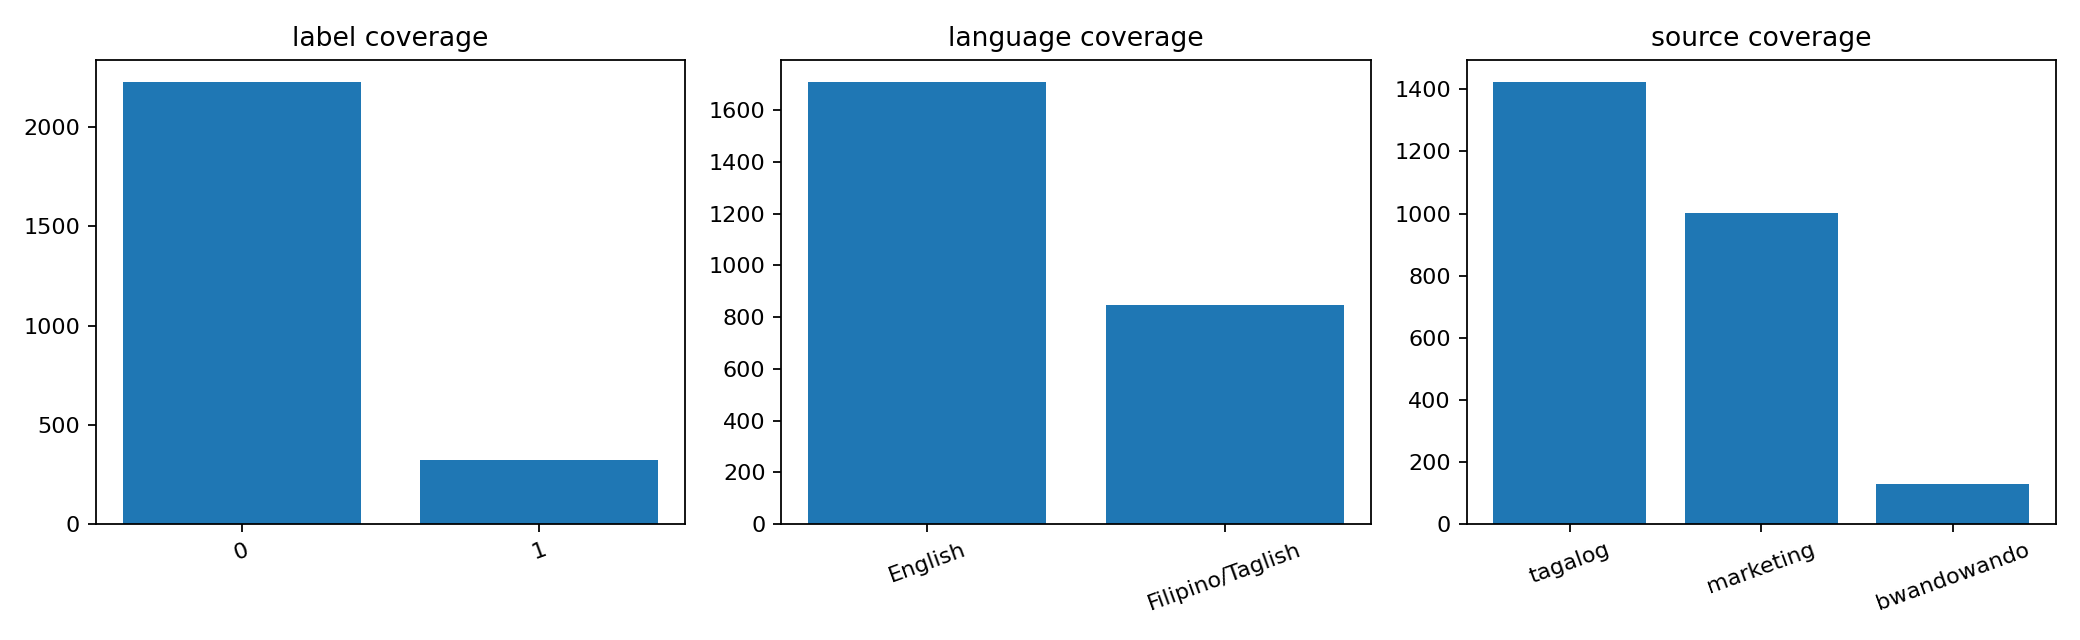

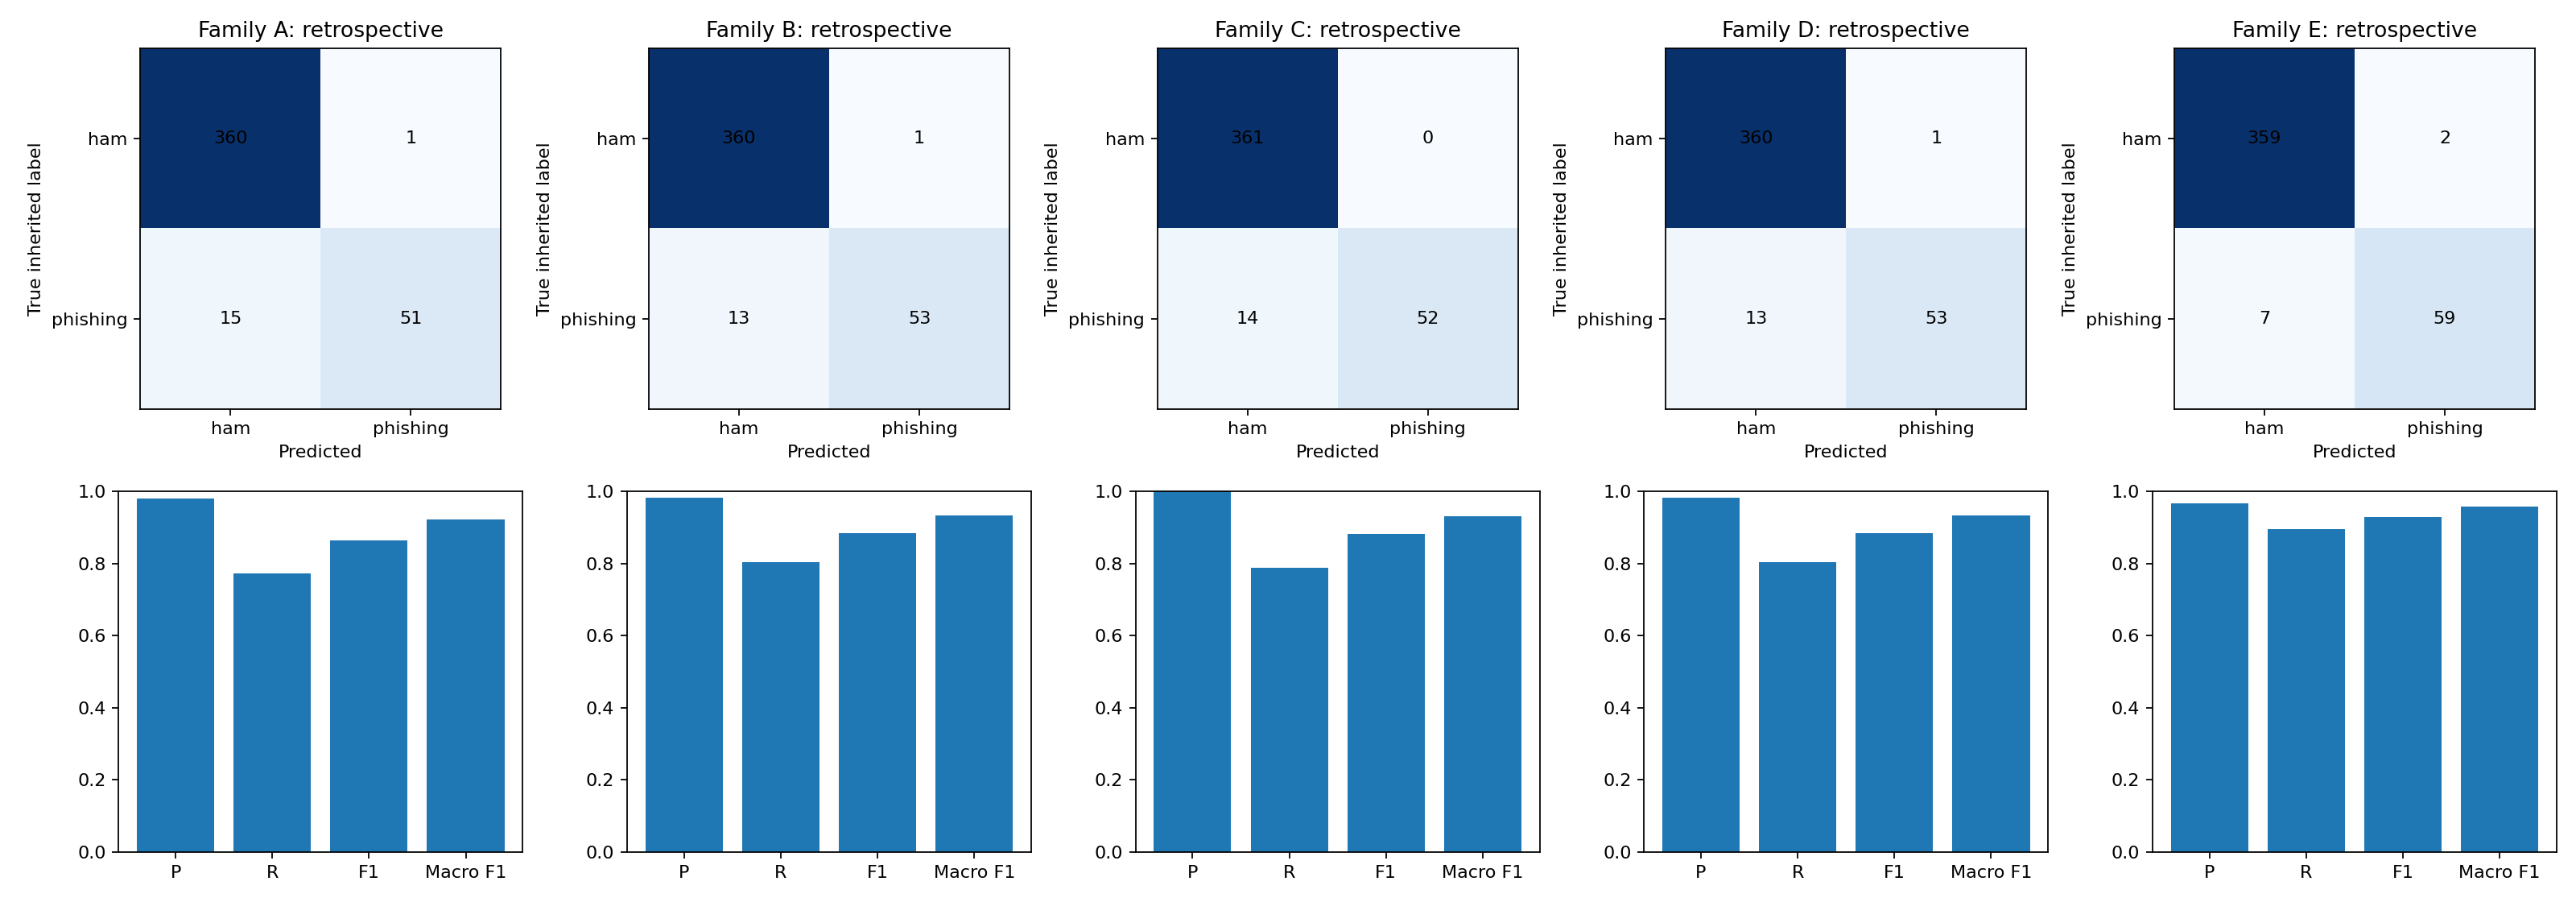

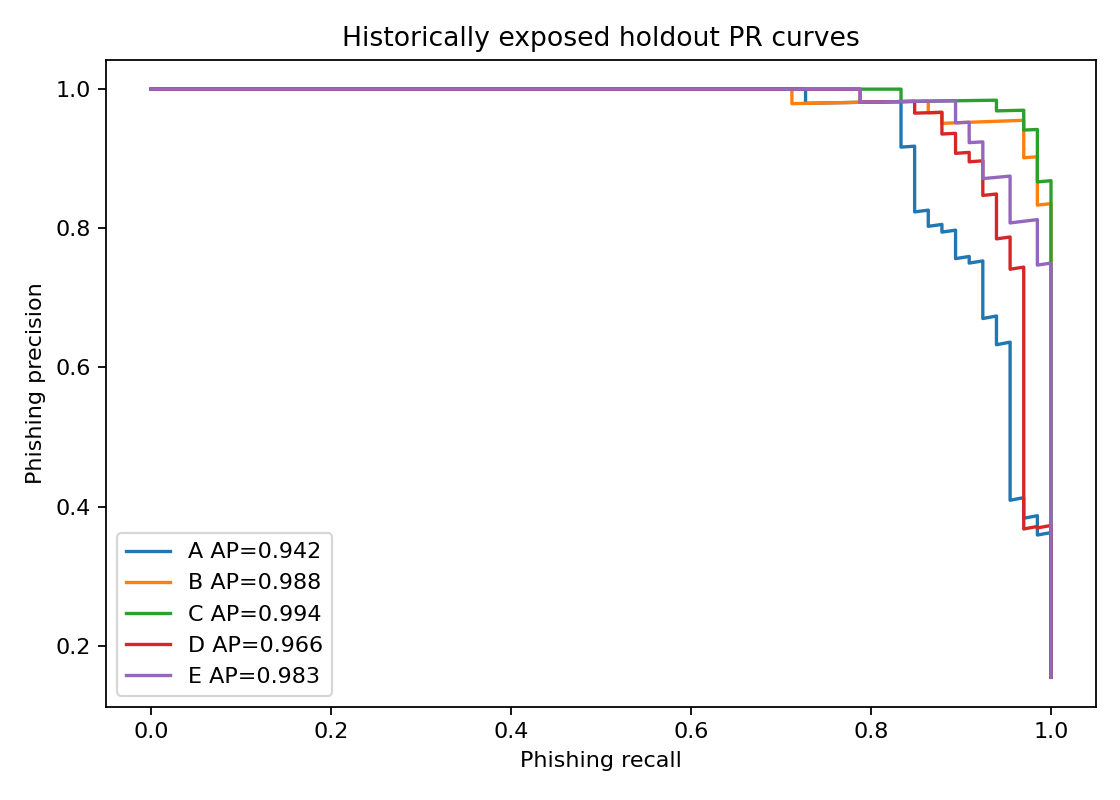

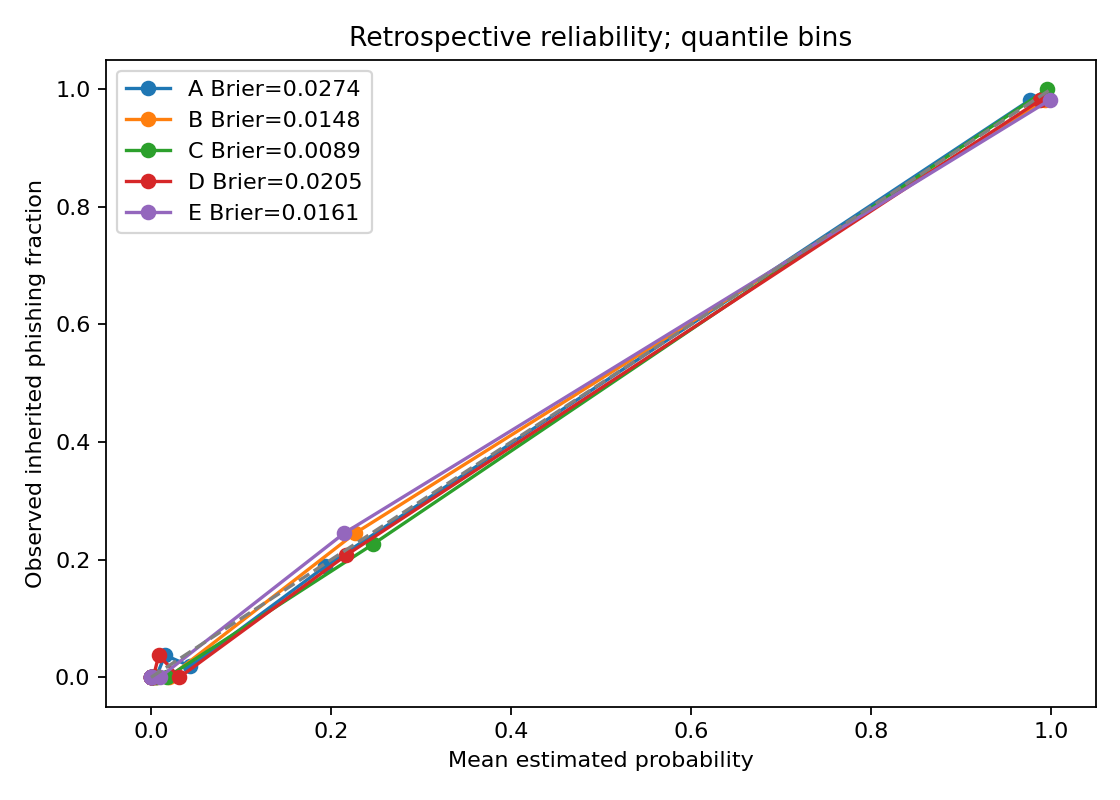

In [7]:
from IPython.display import display, Image
for filename in ('coverage.png','confusion-and-comparison.png','precision-recall.png','reliability.png'):
    display(Image(filename=str(OUTPUT_PATH / filename)))


## Language, subgroup, robustness and uncertainty limits

Read support before metrics. Source/category names do not provide independently
verified phishing or legitimate banking/OTP/conversation labels. Current metadata
merges Filipino/Taglish. Subgroups need >=20 rows and >=5 each class for two-class
metrics; this floor is not a power analysis. Missing categories require human
annotation. Surface robustness edits use validation SMS only, with changed-row
counts; spelling/Taglish substitutions assume preserved meaning and need review.
They are supplementary experiments, not genuine new collected SMS or adversarial
security guarantees. Source/link-only controls and frozen URL removal probe shortcuts.

Repeated fitting seeds keep membership, configuration and threshold unchanged.
Cluster bootstrap intervals condition on fixed fitted predictions and exclude
selection, labels, historical exposure and fitting uncertainty.


In [8]:
print('Selected subgroup diagnostics:', pipeline.load(OUTPUT_PATH/'subgroups-validation.json'))
print('Controlled validation robustness:', pipeline.load(OUTPUT_PATH/'robustness-validation.json'))
print('Shortcut controls:', pipeline.load(OUTPUT_PATH/'shortcut-validation.json'))
print('Source-transfer development stress:', pipeline.load(OUTPUT_PATH/'source-transfer-validation.json'))
print('Fitting seed variation:', selection['seed_variability'])


Selected subgroup diagnostics: {'language:English': {'records': 269, 'ham': 244, 'phishing': 25, 'adequate_two_class_support': True, 'interpretation': 'descriptive inherited subgroup; not independently validated', 'metrics': {'records': 269, 'accuracy': 0.9814126394052045, 'precision': 1.0, 'recall': 0.8, 'f1': 0.8888888888888888, 'macro_f1': 0.9393734505296372, 'average_precision': 0.9280423353027127, 'pr_auc': 0.9267867354169242, 'roc_auc': 0.9859016393442622, 'confusion': {'tn': 244, 'fp': 0, 'fn': 5, 'tp': 20}, 'fpr': 0.0, 'brier': 0.02289857784681399, 'probability_estimate': True}}, 'language:Filipino/Taglish': {'records': 114, 'ham': 110, 'phishing': 4, 'adequate_two_class_support': False, 'interpretation': 'descriptive inherited subgroup; not independently validated', 'metrics': None}, 'source:bwandowando': {'records': 12, 'ham': 0, 'phishing': 12, 'adequate_two_class_support': False, 'interpretation': 'descriptive inherited subgroup; not independently validated', 'metrics': Non

## Offline export, provenance and remaining work

`candidate-model.json` includes ordered vocabulary/IDF/coefficients, independent
word/character block normalization, frozen Python Unicode tables, class order,
threshold and calibration. Android `ResearchLinearScorer` supports this contract;
the production ModelLoader/pointer remain unchanged. Python cases compare sparse
features, scores and threshold decisions at 1e-10 tolerance. JVM checks and optional
instrumentation use this actual export, not a pickle. Runtime applies abstention
for empty/unknown messages and rejects malformed/oversized inputs; report coverage
on real traffic separately from forced mathematical classifier performance.

XLM-R is not trained in the supplied environment: PyTorch/Transformers and a pinned
checkpoint are absent. The existing mBERT experiment is a different family. A future
XLM-R experiment must reuse exact eligible records/splits, use native tokenizer on
original authorized text, document pinned checkpoint/software/resources, compare
ordinary/weighted loss and freeze selection before prospective evaluation.
Masked classical results do not form a fair original-text transformer comparison.

Source attribution/terms and unresolved acquisition/privacy/label review remain in
`docs/source-evidence.md`. No personal/social input is added. Fitted artifacts remain
private; no redistribution or thesis clearance is inferred from public accessibility.

Method references: [TF-IDF 1.6](https://scikit-learn.org/1.6/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html),
[calibration](https://scikit-learn.org/stable/modules/calibration.html),
[XLM-R paper](https://arxiv.org/abs/1911.02116),
[checkpoint provenance](https://huggingface.co/FacebookAI/xlm-roberta-base).


In [9]:
print('Environment and transformer status:', pipeline.load(OUTPUT_PATH/'environment.json'))
print('Saved artifact inventory:', sorted(p.name for p in OUTPUT_PATH.iterdir()))
PARITY_PATH = Path(os.environ.get('SMISHGUARD_PARITY',
    str(OUTPUT_PATH.parent / ('parity-' + selection['selected']['family'] + '-v2'))))
for kind in ('jvm','android'):
    parity=PARITY_PATH / ('research-' + kind + '-parity.json')
    print('Actual '+kind+' parity:', pipeline.load(parity) if parity.exists() else 'Not supplied; run repository parity commands.')


Environment and transformer status: {'python': '3.12.5 (tags/v3.12.5:ff3bc82, Aug  6 2024, 20:45:27) [MSC v.1940 64 bit (AMD64)]', 'unicode': '15.0.0', 'platform': 'Windows-11-10.0.26200-SP0', 'packages': {'numpy': '2.2.6', 'scipy': '1.15.3', 'scikit-learn': '1.6.1', 'matplotlib': '3.10.7', 'joblib': '1.6.0', 'threadpoolctl': '3.7.0'}, 'threads': 1, 'transformer': {'torch_available': False, 'transformers_available': False, 'checkpoint_cached': False, 'status': 'XLM-R not executed: current research env lacks torch/transformers and a pinned local checkpoint. Existing mBERT is a different model.'}}
Saved artifact inventory: ['A-000', 'A-001', 'A-002', 'A-003', 'A-004', 'A-005', 'A-006', 'A-007', 'A-008', 'A-009', 'A-010', 'A-011', 'B-012', 'B-013', 'B-014', 'B-015', 'B-016', 'B-017', 'B-018', 'B-019', 'B-020', 'B-021', 'B-022', 'B-023', 'C-024', 'C-025', 'C-026', 'C-027', 'C-028', 'C-029', 'C-030', 'C-031', 'C-032', 'C-033', 'C-034', 'C-035', 'C-036', 'C-037', 'C-038', 'C-039', 'C-040', '